**Question 1**

The convolution of two functions $f$ and $g$ is defined as the integral: 

$$(f*g)(t) = \int_{-\infty}^{\infty} f(\tau)g(t-\tau) d\tau $$

(a) We can write myConv by setting the array size first, g must be one less the size of f + size of w (i.e. there are $N + M - 1$ nonzero components, where N is the size of f, and M is the size of w). Since the discrete convolution is the integral above approximated as a sum, and can be written like 

$$g[n]= (f * w)[n] = \sum_{k=0}^{N-1} f[k] w[n-k]$$

Note that since here $dt = 1s$ was specified, there was no factor multiplied in, but since we're approximating an integral with a sum there should be a $dt$ weighting.

The value of $g$ is only nonzero when $f$ and $w$ overlap. In numbered indices starting from 0, this means the minimum index they can overlap is 0 and the maximum is when $f[N-1]$ is multiplied by $w[M-1]$, i.e. the index $n = N + M - 2$ and when $k = N - 1$, hence the number of nonzero samples is exactly how many we get between those indices $\Rightarrow N+M-1$ 

(b) To determine the difference from numpy.convolve, the maximum error was taken within 50 trials. Two arrays with a random size between 1 and 20 was made, containing numbers uniformly distributed between $[0,1)$. The final maximum error between myConv and numpy.convolve within 50 trials was $1.78 \times 10^{-15}$

(c) Finally the plot of the runtime between myConv and numpy.convolve is shown below, myConv is significantly slower as the size of the arrays get larger. This is perhaps because myConv has a nested list, which means the runtime is at least $\mathcal{O}(N^2)$

AI: Used to find random.randint used to generate arrays 

Collaborators: None

Max error between myConv and numpy.convolve over 50 trials: 8.881784197001252e-16


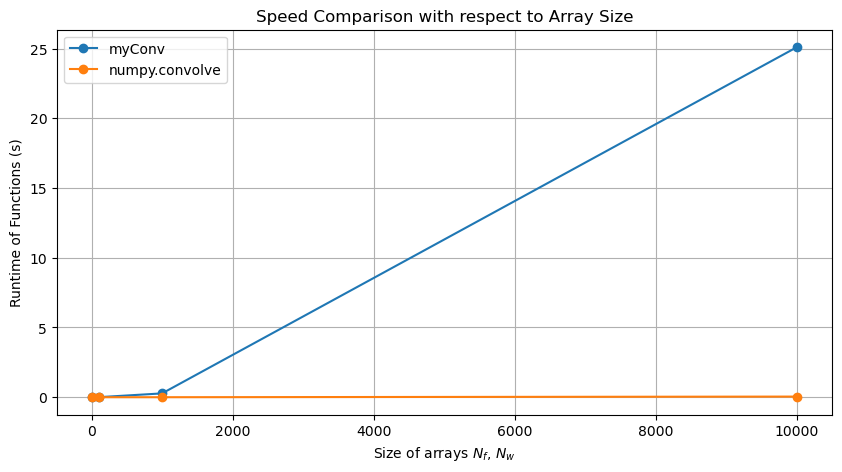

In [19]:
# Question 1: A Discrete Convolution Program

# Import libraries
import numpy as np
import time
import matplotlib.pyplot as plt

# Part a): Write discrete convolution function myConv


def myConv(f, w):
    """
    Outputs the discrete convolution of two inputs 
    Inputs: 
        f, w = arrays
    Outputs:
        Output convolved time series 
    * Note that convolutions are commutative, switching 
    f and w achieve the same result
    """
    g = [0] * (len(f) + len(w) - 1) # Set size of convolved array 

    for n in range(len(g)):
        y = 0 # initialise intermediate sum
        for i in range(len(f)): # i indexes f
            j = n - i  # j indexes w
            if 0 <= j < len(w):  # only add when w[j] exists
                y += f[i] * w[j]
        g[n] = y

    return np.array(g)


# Part b): Generate tests to verify with numpy.convolve

# test within 50 trials what's the maximum error 

max_err = 0.0

for _ in range(50):
    
    # set lengths of test arrays
    
    N = np.random.randint(1, 20) # length of f 
    M = np.random.randint(1, 20) # length of w
    
    # Generate random arrays uniformly distributed between [0,1)
    
    f = np.random.random(N) 
    w = np.random.random(M)

    g_my = myConv(f, w)
    g_np = np.convolve(f, w)

    err = np.max(np.abs(g_my - g_np))  # max absolute difference this trial
    max_err = max(max_err, err)

print("Max error between myConv and numpy.convolve over 50 trials:", max_err)


# Part c): Compare speeds of both functions 

# for simplicity set lengths of f and w as equal

N_speed = [10, 100,1000,10000]

# Store runtimes of both methods

my_conv_time = [] 
numpy_time = []

for length in N_speed: 
    
    # Generate random arrays uniformly distributed between [0,1)
    
    f_time = np.random.random(length) 
    w_time = np.random.random(length)
    
    # Time both methods
    t1_my = time.time()
    g_1 = myConv(f_time, w_time)
    t2_my = time.time()
    
    t1_np = time.time()
    g_2 = np.convolve(f_time, w_time)
    t2_np = time.time()
    
    # append final times into cumulative lists 
    my_conv_time.append(t2_my - t1_my)
    numpy_time.append(t2_np - t1_np)

# Plot timing results 

plt.figure(figsize = (10,5))
plt.plot(N_speed, my_conv_time, 'o-', label = 'myConv')
plt.plot(N_speed, numpy_time, 'o-', label = 'numpy.convolve')
plt.xlabel(r'Size of arrays $N_f$, $N_w$')
plt.ylabel('Runtime of Functions (s)')
plt.title('Speed Comparison with respect to Array Size')
plt.grid()
plt.legend()
plt.show()